# #252 — historical proxy and poll-start temporal semantics (v3)

Executed candidate profiling receipt. Historical `initial`/`10h`/`1h` coverage is split by market and field role. Forward rows use the collector poll-start clock against the current schedule reference; that clock is not received-at, commit-at, reschedule-as-of, or per-cell source authority.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
import pandas as pd

ROOT = Path.cwd()
package = ROOT / 'results' / 'bj252_unified_temporal_semantics_v3'
manifest = json.loads((package / 'MANIFEST.json').read_text(encoding='utf-8'))
print(package.relative_to(ROOT))
print({key: manifest[key] for key in ['clock_authority', 'schedule_authority', 'cell_lineage']})

results/bj252_unified_temporal_semantics_v3
{'clock_authority': 'POLL_STARTED_NOT_RECEIVED_OR_COMMITTED', 'schedule_authority': 'CURRENT_SCHEDULE_REFERENCE_NOT_RESCHEDULE_ASOF', 'cell_lineage': 'LOCAL_MERGED_UPSTREAM_CELL_SOURCE_UNKNOWN'}


In [2]:
coverage = pd.read_csv(package / 'tables' / 'cutoff_coverage.csv')
metrics = [
    'fixture_count', 'available_fixture_count', 'total_cell_count',
    'storage_present_cell_count', 'valid_sp_cell_count',
    'model_available_cell_count',
]
cutoff_totals = coverage.groupby('lead_hours', as_index=False)[metrics].sum()
cutoff_totals

,lead_hours,fixture_count,available_fixture_count,total_cell_count,storage_present_cell_count,valid_sp_cell_count,model_available_cell_count
0,1,5494,153,16482,459,459,459
1,6,5494,153,16482,459,459,459
2,12,5494,56,16482,285,186,168
3,24,5494,0,16482,0,0,0


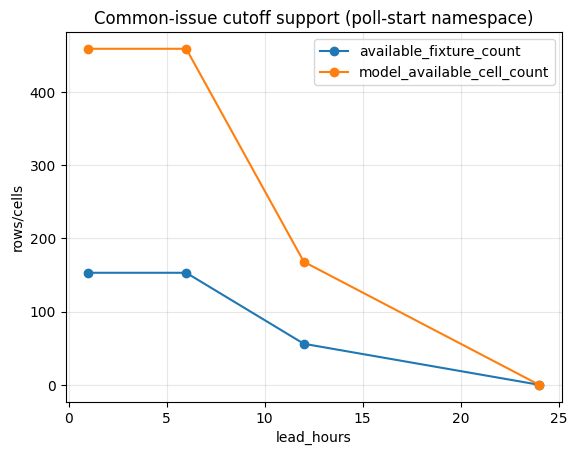

In [3]:
ax = cutoff_totals.plot(
    x='lead_hours',
    y=['available_fixture_count', 'model_available_cell_count'],
    marker='o',
    title='Common-issue cutoff support (poll-start namespace)',
)
ax.set_ylabel('rows/cells')
ax.grid(alpha=0.3)
plt.show()

In [4]:
drops = pd.read_csv(package / 'tables' / 'cutoff_drop_reasons.csv')
drop_totals = drops.groupby(['lead_hours', 'drop_reason'])['fixture_count'].sum().unstack(fill_value=0)
drop_totals

drop_reason,AVAILABLE,INVALID_VALUE,NO_OBSERVATION_BY_CUTOFF
lead_hours,,,
1,153,0,5341
6,153,0,5341
12,56,39,5399
24,0,0,5494


In [5]:
segment = pd.read_csv(package / 'tables' / 'segment_selection.csv')
duration = pd.read_csv(package / 'tables' / 'issue_duration.csv')
print('Segment dispositions:')
print(segment.groupby('drop_reason').size())
print('Issue duration hours:')
duration['issue_duration_hours'].describe()

Segment dispositions:
drop_reason
AVAILABLE                                3393
INVALID_VALUE                              18
NO_OBSERVATION_BY_CUTOFF                 1677
OBSERVATION_UNAVAILABLE_OR_INCOMPLETE     406
dtype: int64
Issue duration hours:


count     32.000000
mean     123.406771
std       37.313577
min       76.000000
25%      101.312500
50%      104.250000
75%      152.750000
max      201.000000
Name: issue_duration_hours, dtype: float64

In [6]:
proxy = pd.read_csv(package / 'tables' / 'proxy_horizon_market_summary.csv')
proxy[[
    'snapshot_horizon', 'market', 'field_role', 'p34_m3_compatible',
    'fixture_count', 'complete_consensus_rows', 'available_value_cells',
]]

,snapshot_horizon,market,field_role,p34_m3_compatible,fixture_count,complete_consensus_rows,available_value_cells
0,initial,asian_handicap,HANDICAP_LINE_TWO_PRICE_DIAGNOSTIC,False,195269,192338,577693
1,initial,euro_1x2,EURO_1X2_OUTCOME_PROXY,True,195269,192409,577602
2,initial,kelly_1x2,KELLY_1X2_DIAGNOSTIC,False,195269,135429,407205
3,initial,over_under,TOTAL_LINE_TWO_PRICE_DIAGNOSTIC,False,195269,192286,577713
4,10h,asian_handicap,HANDICAP_LINE_TWO_PRICE_DIAGNOSTIC,False,195269,190634,573818
5,10h,euro_1x2,EURO_1X2_OUTCOME_PROXY,True,195269,192297,577035
6,10h,kelly_1x2,KELLY_1X2_DIAGNOSTIC,False,195269,135417,406355
7,10h,over_under,TOTAL_LINE_TWO_PRICE_DIAGNOSTIC,False,195269,191689,575942
8,1h,asian_handicap,HANDICAP_LINE_TWO_PRICE_DIAGNOSTIC,False,195269,192550,577665
9,1h,euro_1x2,EURO_1X2_OUTCOME_PROXY,True,195269,192441,577332
